# 1. CADRAGE

**Conntexte** : Les données brutes contiennent 7043 lignes (clients) et 21 colonnes (fonctionnalités) incluant un Churn(Resiliation).

**Objectif** : prédire quels clients d’un opérateur télécom vont résilier leur abonnement, pour que l’entreprise puisse agir avant leur départ. est notre cible

**Variables explicatives** :  20 variables**Cible** : `« Churn »`

**Evaluation** : 

**Démarche** : nettoyage et EDA, split stratifié, prétraitement dans un pipeline (sans fuite de données), comparaison de modèles en validation croisée, optimisation par `GridSearchCV`, évaluation finale sur le test, interprétation.

**Contrainte métier** : Rater un client qui va résilier coûte cher.

# 2. IMPORTS

## 2.1. LIBRAIRIES

### Données et affichage

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###  Séparation et validation

In [2]:
from sklearn.model_selection import (
    train_test_split, # separer train/test une seule fois
    StratifiedKFold, # validation croisee stratifiee
    cross_validate, # validation croisee avec plusieurs metriques + temps
    GridSearchCV, # recherche exhaustive des meilleurs hyperparametres
)

### Préparation des données

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, LabelEncoder # Pour encodage
from sklearn.compose import ColumnTransformer
from sklearn.base import clone # Verification apres encodage

### Modeles de classification

In [4]:
from sklearn.dummy import DummyClassifier # Baseline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

### Evaluation

In [5]:
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer,
    precision_score,
)
from sklearn.inspection import permutation_importance

## 2.2. RANDOM_STATE

In [6]:
RANDOM_STATE = 42

## 2.3. OPTIONS D"AFFICHAGE

In [7]:
# Afficher toutes les colonnes
pd.set_option("display.max_columns", None)

# 3. CHARGEMENT DES DONNEES

In [8]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f"Taille : {df.shape[0]} lignes | {df.shape[1]} colonnes")

Taille : 7043 lignes | 21 colonnes


In [9]:
print('5 premieres lignes : ')
df.head()

5 premieres lignes : 


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
print('Informations : ')
df.info()

Informations : 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non

**Lecture rapide :**
- 3 variables numériques (`MonthlyCharges`, `tenure`, `SeniorCitizen`)
- 17 variables catégorielles , 1 variable categorielle cible (`Churn`)
- Pas de valeur manquante visible dans `df.info()` (7043 valeurs non nulles partout), a confirmer plus bas.

# 4. NETTOYAGE ET QUALITE

### Valeurs manquantes

In [11]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Doublons

In [12]:
df.duplicated().sum()

np.int64(0)

### Renommage des colonnes en fr

In [13]:
noms = {
    "customerID": "id_client",
    "gender": "genre",
    "SeniorCitizen": "senior",
    "Partner": "en_couple",
    "Dependents": "personnes_a_charge",
    "tenure": "anciennete_mois",
    "PhoneService": "service_telephone",
    "MultipleLines": "lignes_multiples",
    "InternetService": "service_internet",
    "OnlineSecurity": "securite_en_ligne",
    "OnlineBackup": "sauvegarde_en_ligne",
    "DeviceProtection": "protection_appareil",
    "TechSupport": "support_technique",
    "StreamingTV": "streaming_tv",
    "StreamingMovies": "streaming_films",
    "Contract": "type_contrat",
    "PaperlessBilling": "facture_dematerialisee",
    "PaymentMethod": "mode_paiement",
    "MonthlyCharges": "frais_mensuels",
    "TotalCharges": "frais_totaux",
    "Churn": "resiliation",
}

df = df.rename(columns=noms)

#### Verif

In [14]:
df.columns

Index(['id_client', 'genre', 'senior', 'en_couple', 'personnes_a_charge',
       'anciennete_mois', 'service_telephone', 'lignes_multiples',
       'service_internet', 'securite_en_ligne', 'sauvegarde_en_ligne',
       'protection_appareil', 'support_technique', 'streaming_tv',
       'streaming_films', 'type_contrat', 'facture_dematerialisee',
       'mode_paiement', 'frais_mensuels', 'frais_totaux', 'resiliation'],
      dtype='object')

### Valeurs unique

In [15]:
# Suprression de la colonne id
df.drop(columns='id_client', inplace=True)

In [16]:
cols_cat = df.select_dtypes(include="object")

for col in cols_cat:
    print(f"{col} -------------------- {df[col].unique()}")
    print()

genre -------------------- ['Female' 'Male']

en_couple -------------------- ['Yes' 'No']

personnes_a_charge -------------------- ['No' 'Yes']

service_telephone -------------------- ['No' 'Yes']

lignes_multiples -------------------- ['No phone service' 'No' 'Yes']

service_internet -------------------- ['DSL' 'Fiber optic' 'No']

securite_en_ligne -------------------- ['No' 'Yes' 'No internet service']

sauvegarde_en_ligne -------------------- ['Yes' 'No' 'No internet service']

protection_appareil -------------------- ['No' 'Yes' 'No internet service']

support_technique -------------------- ['No' 'Yes' 'No internet service']

streaming_tv -------------------- ['No' 'Yes' 'No internet service']

streaming_films -------------------- ['No' 'Yes' 'No internet service']

type_contrat -------------------- ['Month-to-month' 'One year' 'Two year']

facture_dematerialisee -------------------- ['Yes' 'No']

mode_paiement -------------------- ['Electronic check' 'Mailed check' 'Bank transfer

**Remarque** : La colonne frais totaux est une variable catégorielles ce qui ne passe pas.

In [17]:
# Conversion
df["frais_totaux"] = pd.to_numeric(df["frais_totaux"], errors="coerce")

**Verification sur les Nan**

In [18]:
print("Valeurs NaN apres conversion : ")
df['frais_totaux'].isna().sum()

Valeurs NaN apres conversion : 


np.int64(11)

In [19]:
# Suppression des lignes 
df = df.dropna(subset=["frais_totaux"])

In [20]:
print("Vérification finale : ")
df['frais_totaux'].isna().sum()

Vérification finale : 


np.int64(0)

#### **Conclusion** : `Le jeu de données est propre`.

# 5. EDA

###  Distribution de la variable cible

--------------------------------------
Proportion de chaque classe :
resiliation
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64
--------------------------------------
Visualisation


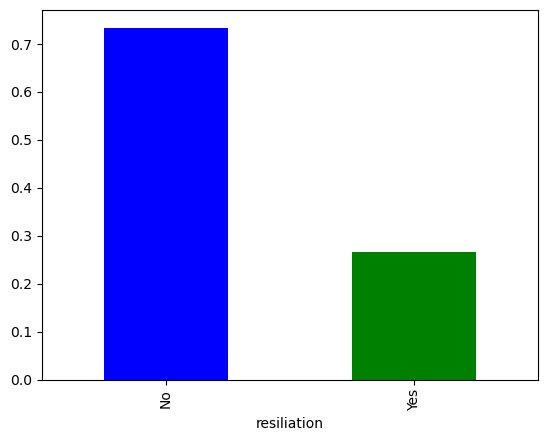

In [21]:
print("--------------------------------------")

prop = df["resiliation"].value_counts(normalize=True)
print(f"Proportion de chaque classe :\n{prop}")

print("--------------------------------------")

print("Visualisation")
prop.plot.bar(color=['blue', 'green'])

plt.show()

#### **Remarque** : **`Classes déséquilbrées`**

### Statistiques descriptives

In [22]:
df.describe()

,senior,anciennete_mois,frais_mensuels,frais_totaux
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441
std,0.368844,24.545260,30.085974,2266.771362
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.862500,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


### Distribution des variables catégorielles

genre,
en_couple,
personnes_a_charge,
service_telephone,
lignes_multiples,
service_internet ,
securite_en_ligne,
sauvegarde_en_ligne,
protection_appareil ,
support_technique ,
streaming_tv --,
streaming_films ,
type_contrat ,
facture_dematerialisee, 
mode_paiement,
resiliation -,

In [23]:
cat_dist = df.select_dtypes(include="object").columns.drop('resiliation')

for c in cat_dist :
    print(df[c].value_counts(normalize=True))
    print()

genre
Male      0.504693
Female    0.495307
Name: proportion, dtype: float64

en_couple
No     0.517491
Yes    0.482509
Name: proportion, dtype: float64

personnes_a_charge
No     0.701507
Yes    0.298493
Name: proportion, dtype: float64

service_telephone
Yes    0.903299
No     0.096701
Name: proportion, dtype: float64

lignes_multiples
No                  0.481371
Yes                 0.421928
No phone service    0.096701
Name: proportion, dtype: float64

service_internet
Fiber optic    0.440273
DSL            0.343572
No             0.216155
Name: proportion, dtype: float64

securite_en_ligne
No                     0.497298
Yes                    0.286547
No internet service    0.216155
Name: proportion, dtype: float64

sauvegarde_en_ligne
No                     0.438993
Yes                    0.344852
No internet service    0.216155
Name: proportion, dtype: float64

protection_appareil
No                     0.439989
Yes                    0.343857
No internet service    0.216155
Na

**Lecture rapide** : 
 - `La colonne sur service_telephone a un ratio 9(Y)-1(N)`
 - `Le genre et la situation en couple sont équilibrés`
 - `Le multi classe (3+) est aussi en général équilibré`

### Correlations entre les variables numériques

In [24]:
cols_num = df.select_dtypes(include="number").columns
print(cols_num)

Index(['senior', 'anciennete_mois', 'frais_mensuels', 'frais_totaux'], dtype='object')


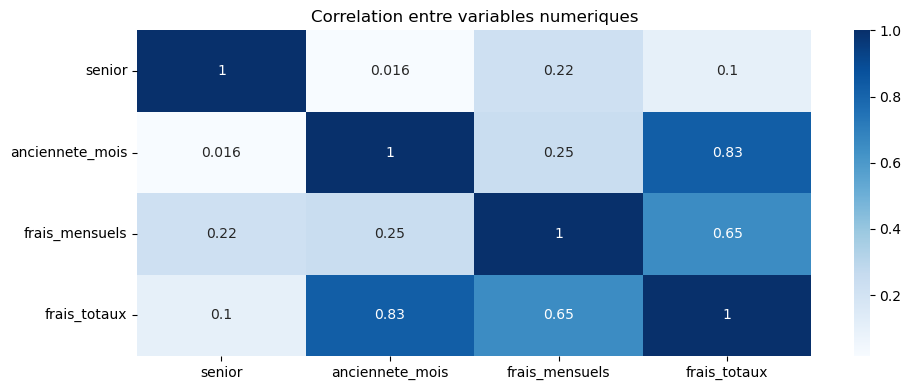

In [25]:
corr = df[['senior', 'anciennete_mois', 'frais_mensuels', 'frais_totaux']].corr()

plt.figure(figsize=(10,4))

sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("Correlation entre variables numeriques")
plt.tight_layout()

plt.show()

**Remarque** : frais_totaux est fortement corrélée à anciennete_mois (autour de 0.83) et à frais_mensuels (autour de 0.65). C’est logique : `frais totaux ≈ ancienneté × frais mensuels`.

**Choix personnel** : Je décide de garder frais_totaux malgré lea corr a 83 car les modeles d'arbre suporte la redondance. J'aurais pu faire une autre corr avec la variable cible pour me positionner mais je n'aimerais pas me retrouver dans un `cercle de correlation et de causalité`.

### Variables vs Cible

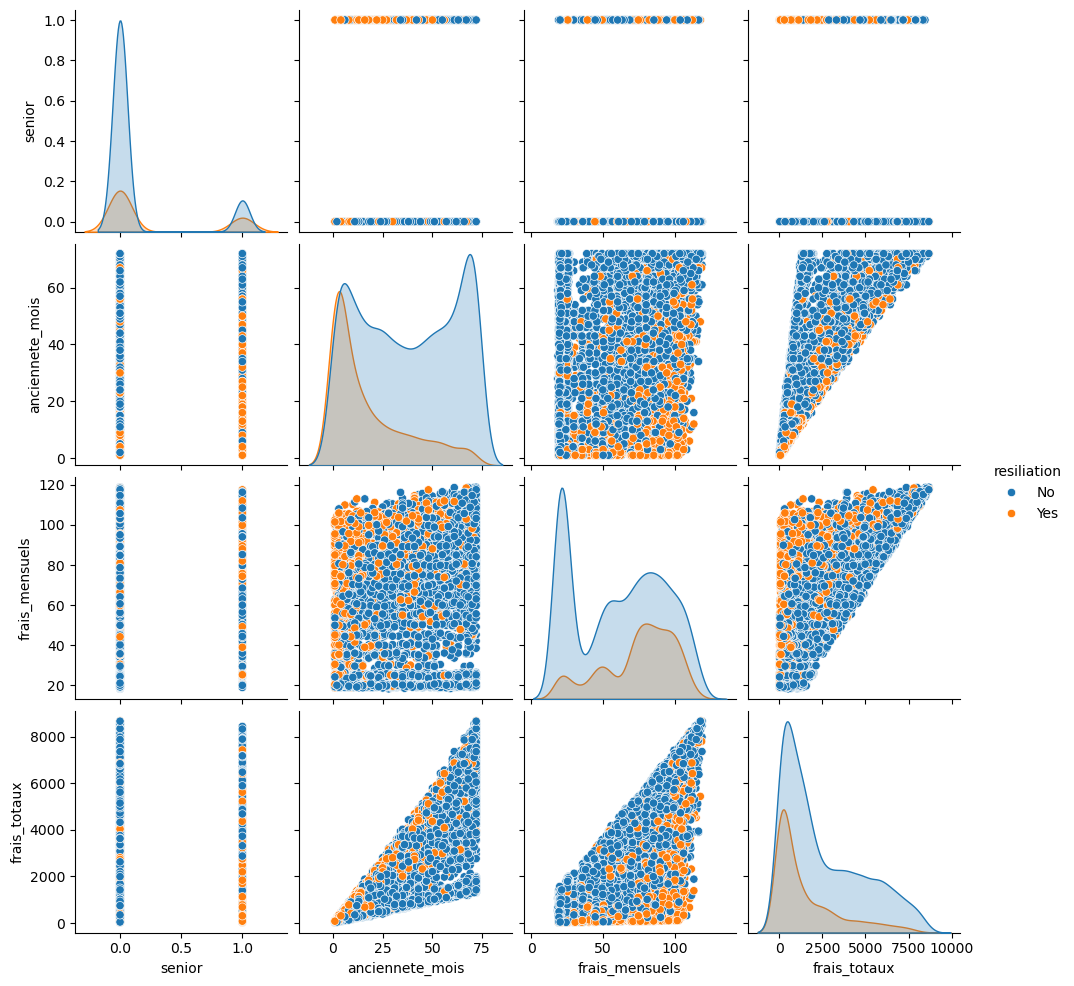

In [26]:
sns.pairplot(data = df , hue='resiliation')

plt.show()

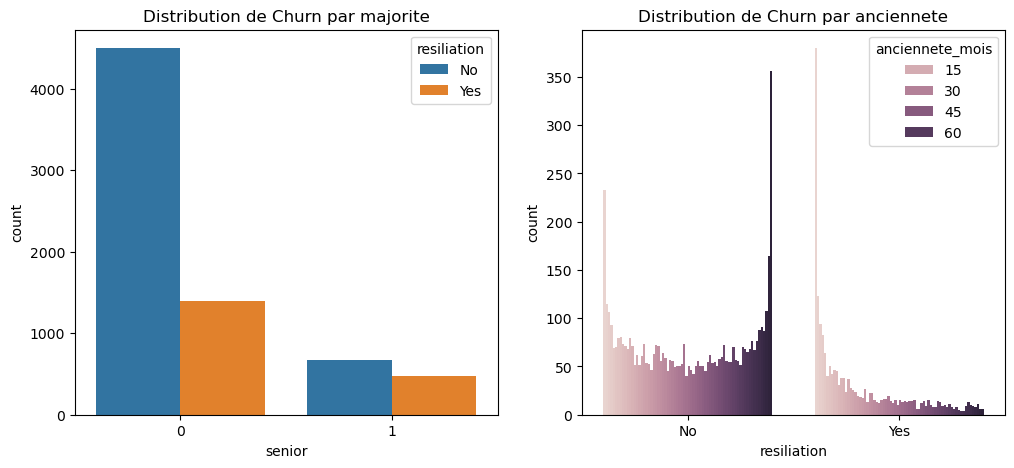

In [27]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.countplot(x='senior', data=df, hue='resiliation')
plt.title("Distribution de Churn par majorite")

plt.subplot(1,2,2)
sns.countplot(x='resiliation', data=df, hue='anciennete_mois')
plt.title("Distribution de Churn par anciennete")

plt.show()

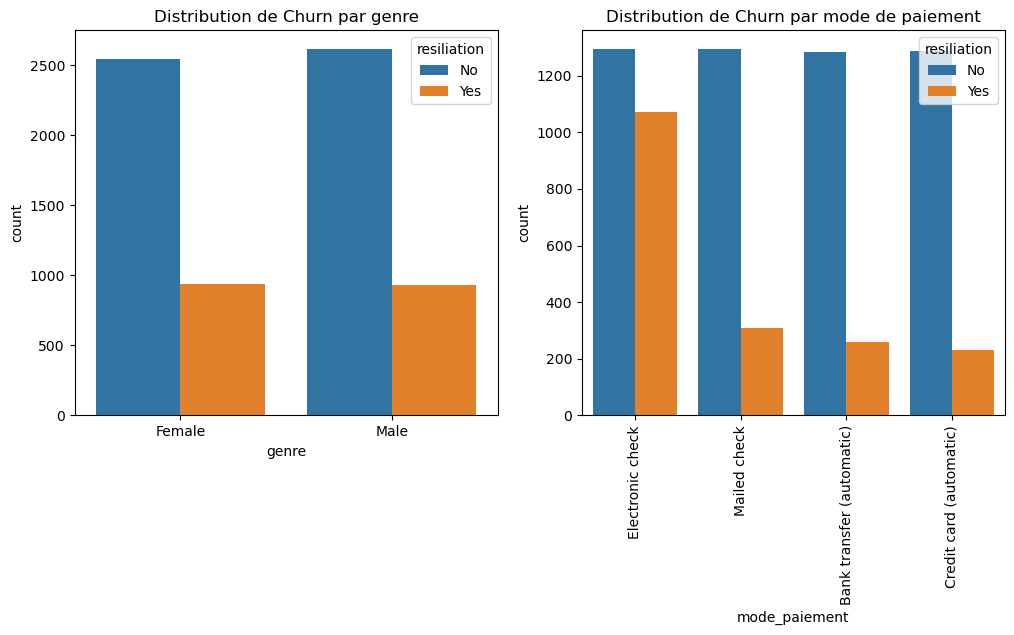

In [28]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.countplot(x='genre', data=df, hue='resiliation')
plt.title("Distribution de Churn par genre")

plt.subplot(1,2,2)
sns.countplot(x='mode_paiement', data=df, hue='resiliation')
plt.title("Distribution de Churn par mode de paiement")
plt.xticks(rotation=90)

plt.show()

**Lecture rapide** :
 - Les mineurs (senior = 0) ont tendance a moins resilier que les adultes (bien sur d'autres variables entre en compte dans cette retention)
 - Une grande majorite des personnes deja installee (anciennete) ont tendance a rester
 - Le sexe n'a pas d'impact sur la resiliation (donc je compte le supprimer)
 - Les personnes avec un electronic check on plus tendance a resilier

In [29]:
# Suppression de la colonne genre
df.drop(columns='genre', inplace=True)

In [30]:
df.columns

Index(['senior', 'en_couple', 'personnes_a_charge', 'anciennete_mois',
       'service_telephone', 'lignes_multiples', 'service_internet',
       'securite_en_ligne', 'sauvegarde_en_ligne', 'protection_appareil',
       'support_technique', 'streaming_tv', 'streaming_films', 'type_contrat',
       'facture_dematerialisee', 'mode_paiement', 'frais_mensuels',
       'frais_totaux', 'resiliation'],
      dtype='object')

### BOXPLOTS

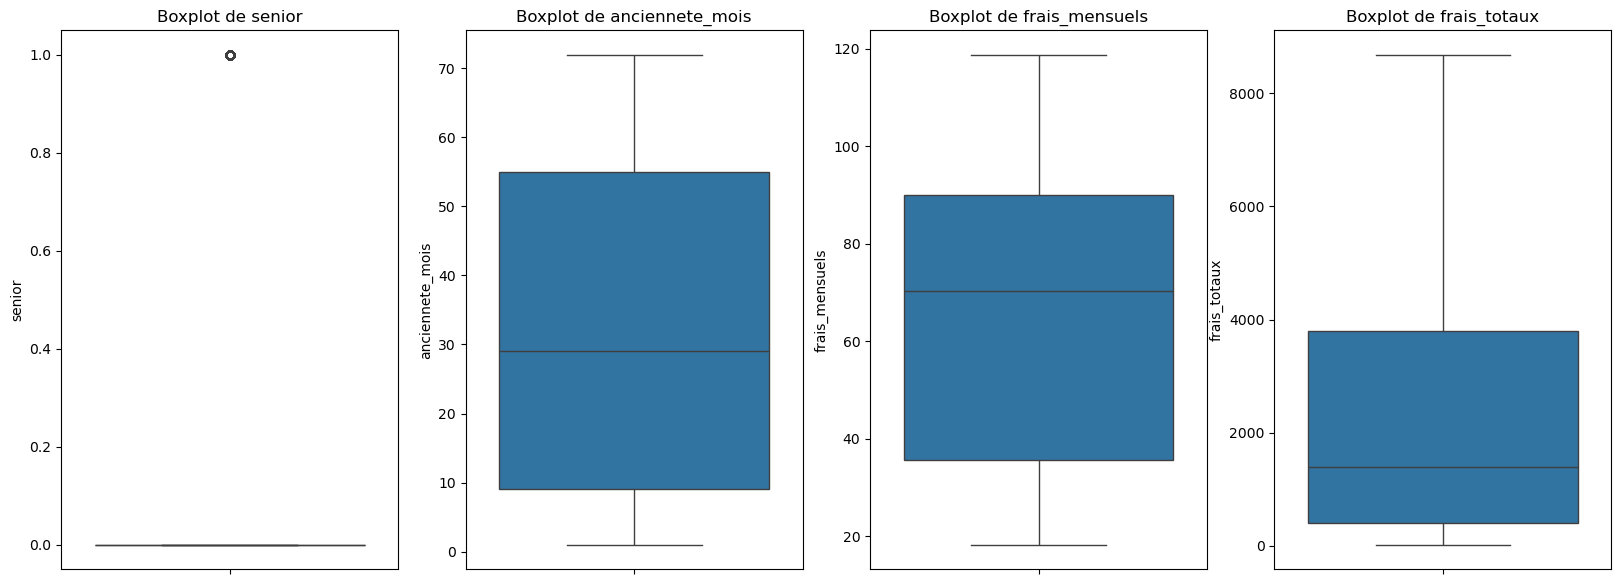

In [40]:
plt.figure(figsize=(20,7))

for c, i in zip(cols_num, [1,2,3,4]) : 
    plt.subplot(1,4,i)
    sns.boxplot(y=c, data=df)
    plt.title(f"Boxplot de {c}")
    

**Remarque** : Rien d'anormal détecté.

# 6. SEPARATION DES DONNEES